**Author**: JW Debelius (justine.debelius@jhu.edu)<br>
**Project**: 017-Arg<br>
**Enviroment**: <br>
**Creation Date**:  November 2025

This notebook will build taxa plots to show how many participants have which taxonomic composition at whcih time point. We'll build these by phylum and family, based on the standards suggested by microshades. ...I'm going to use the microshades standard palette here because I already use the microshades cvd, but... here we are?

In [1]:
import os

import biom
import numpy as np
import pandas as pd
import scipy
import skbio

from matplotlib import rcParams
import matplotlib.pyplot as plt
import matplotlib.colors as mpc
from matplotlib.ticker import StrMethodFormatter
import seaborn as sn

from qiime2 import Artifact, Metadata, Visualization

import qiime2.plugins.feature_table.actions as q2_feature_table

%matplotlib inline
rcParams['font.sans-serif'] = ['Helvetica', 'Arial']
rcParams['pdf.fonttype'] = 42

/Users/jwd/miniconda3/envs/arg-amplicon-2025.7/lib/python3.10/site-packages/q2_demux/_summarize/_visualizer.py:11: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


# Loads data

In [2]:
meta = pd.read_csv('final-data/01.metadata/analysis_sample_meta.tsv',
                     sep='\t',
                     dtype=str)
meta.set_index('sample-id', inplace=True)
meta.shape

(473, 36)

In [3]:
track_step = pd.read_csv('final-data/01.metadata/track_all_samples.tsv',
                            sep='\t',
                            dtype=str)
track_step[['drop_count', 'drop_step']] = \
    track_step[['drop_count', 'drop_step']].astype(float).astype(int)
track_step['timepoint'] = track_step['timepoint'].astype(float)
track_step.set_index(['abx_code2', 'host_subject_id', 'sample-id'],
                     inplace=True)
track_step.replace({'marker': {'X': 'x'}}, inplace=True)
track_step.shape

(609, 9)

In [4]:
track_step2 = track_step.loc[track_step.index.to_frame()['sample-id'].isin(meta.index)].copy()

# Identifies most abundant phyla and families

We're going to work at phylum/family level here because there are not enough colors to accurately see species in a stacked barplot.

We can reasonably have 5 phyla (with an "other" group identiying clades not in the main phyla) and then about 5 shades (families) within each clade.

In [5]:
table_q2 = Artifact.load('final-data/02.tables/matched-species-gtdb.qza')
table_q2, = q2_feature_table.filter_samples(table_q2, metadata=Metadata(meta))


In [6]:
table_a = table_q2.view(biom.Table)
table_a.add_metadata(meta.to_dict(orient='index'), axis='sample')
table_n = table_a.copy().norm(axis='sample')
table_id = table_n.collapse(lambda id_, md: md['host_subject_id'],
                            axis='sample',
                            norm=True)
table_avg = table_id.collapse(lambda id_, md: 'all',
                             axis='sample',
                             norm=True)

In [7]:
table_avgp = table_avg.collapse(lambda id_, md: id_.split(';')[1],
                             axis='observation',
                             norm=False)
table_avgp.filter(lambda v, id_, md: (v > 0.015).all(), axis='observation')
top_phyla = table_avgp.to_dataframe().sparse.to_dense()
top_phyla.sort_values('all', ascending=False, inplace=True)
top_phyla

,all
p__Bacteroidota,0.591928
p__Firmicutes_A,0.309296
p__Proteobacteria,0.027735
p__Firmicutes,0.024497
p__Verrucomicrobiota,0.016671


Within each family, we're going to identify the top families, where top families have a mean relative abundance of 1% or higher. 

In [8]:
table_avgf = table_avg.collapse(lambda id_, md: ';'.join(id_.split(';')[1:5]),
                                axis='observation',
                                norm=False)
table_avgf.filter(lambda v, id_, md: (v > 0.01).all(),
                  axis='observation')
top_families = table_avgf.to_dataframe().sparse.to_dense()
top_families['phylum'] = \
    top_families.index.to_frame()[0].apply(lambda x: x.split(';')[0])
top_families['phylum'] = top_families['phylum'].mask(
    ~top_families['phylum'].isin(top_phyla.index), 'p__Other')
top_families['phylum_avg'] = \
    top_families['phylum'].replace(top_phyla['all'].astype(str))
top_families['phylum_avg'] = top_families['phylum_avg'].astype(float)
top_families.sort_values(['phylum_avg', 'all'], ascending=False, inplace=True)
top_families['top_count'] = 1
top_families['top_count'] = \
    top_families.groupby('phylum')['top_count'].cumsum()
top_families

,all,phylum,phylum_avg,top_count
p__Bacteroidota;c__Bacteroidia;o__Bacteroidales;f__Bacteroidaceae,0.460087,p__Bacteroidota,0.591928,1
p__Bacteroidota;c__Bacteroidia;o__Bacteroidales;f__Rikenellaceae,0.060608,p__Bacteroidota,0.591928,2
p__Bacteroidota;c__Bacteroidia;o__Bacteroidales;f__Tannerellaceae,0.031549,p__Bacteroidota,0.591928,3
p__Bacteroidota;c__Bacteroidia;o__Bacteroidales;f__Marinifilaceae,0.011580,p__Bacteroidota,0.591928,4
p__Bacteroidota;c__Bacteroidia;o__Bacteroidales;f__Barnesiellaceae,0.010342,p__Bacteroidota,0.591928,5
p__Firmicutes_A;c__Clostridia;o__Lachnospirales;f__Lachnospiraceae,0.124063,p__Firmicutes_A,0.309296,1
p__Firmicutes_A;c__Clostridia;o__Oscillospirales;f__Ruminococcaceae,0.079513,p__Firmicutes_A,0.309296,2
p__Firmicutes_A;c__Clostridia;o__Oscillospirales;f__Oscillospiraceae,0.051930,p__Firmicutes_A,0.309296,3
p__Firmicutes_A;c__Clostridia;o__Christensenellales;f__CAG-74,0.020468,p__Firmicutes_A,0.309296,4
p__Firmicutes_A;c__Clostridia;o__Oscillospirales;f__Acutalibacteraceae,0.010720,p__Firmicutes_A,0.309296,5


Because we can only keep 4 families (plus an other category) with our colormap, we're going to drop the 5th ranked category. 

In [9]:
top_families_c = top_families.loc[top_families['top_count'] < 5].copy()
top_families_c

,all,phylum,phylum_avg,top_count
p__Bacteroidota;c__Bacteroidia;o__Bacteroidales;f__Bacteroidaceae,0.460087,p__Bacteroidota,0.591928,1
p__Bacteroidota;c__Bacteroidia;o__Bacteroidales;f__Rikenellaceae,0.060608,p__Bacteroidota,0.591928,2
p__Bacteroidota;c__Bacteroidia;o__Bacteroidales;f__Tannerellaceae,0.031549,p__Bacteroidota,0.591928,3
p__Bacteroidota;c__Bacteroidia;o__Bacteroidales;f__Marinifilaceae,0.011580,p__Bacteroidota,0.591928,4
p__Firmicutes_A;c__Clostridia;o__Lachnospirales;f__Lachnospiraceae,0.124063,p__Firmicutes_A,0.309296,1
p__Firmicutes_A;c__Clostridia;o__Oscillospirales;f__Ruminococcaceae,0.079513,p__Firmicutes_A,0.309296,2
p__Firmicutes_A;c__Clostridia;o__Oscillospirales;f__Oscillospiraceae,0.051930,p__Firmicutes_A,0.309296,3
p__Firmicutes_A;c__Clostridia;o__Christensenellales;f__CAG-74,0.020468,p__Firmicutes_A,0.309296,4
p__Proteobacteria;c__Gammaproteobacteria;o__Burkholderiales;f__Burkholderiaceae,0.012233,p__Proteobacteria,0.027735,1
p__Proteobacteria;c__Alphaproteobacteria;o__RF32;f__CAG-239,0.011472,p__Proteobacteria,0.027735,2


And then we're going to collapse the data to get our final table for plotting.

In [10]:
def _collapse_taxa(id_, md):
    """
    Collapse the taxonomy for plotting
    """
    phylum = id_.split(';')[1]
    family = ';'.join(id_.split(';')[1:5])

    if family in top_families_c.index:
        return family
    elif phylum in top_phyla.index:
        return f'{phylum};c__Other;o__Other;f__Other'
    else:
        return 'p__Other;c__Other;o__Other;f__Other'

In [11]:
table_fam_col = table_n.collapse(_collapse_taxa, axis='observation', norm=False)
table_fam_col = table_fam_col.to_dataframe().sparse.to_dense()
table_fam_col['avg'] = top_families_c['all']
table_fam_col['phylum'] = \
    table_fam_col.index.to_frame()[0].apply(lambda x: x.split(';')[0])
table_fam_col['phylum_avg'] = \
    table_fam_col['phylum'].replace(top_phyla['all'].astype(str))
table_fam_col['phylum_avg'] = \
    table_fam_col['phylum_avg'].replace({"p__Other": np.nan}).astype(float)
table_fam_col.replace({np.nan: 0}, inplace=True)
table_fam_col['phylum_avg2'] = table_fam_col['phylum_avg'] + \
    table_fam_col['phylum'].isin(['p__Firmicutes_A']) * 0.5
table_fam_col.sort_values(['phylum_avg2', 'avg'],
                          ascending=False, 
                          inplace=True)
table_fam_avg = table_fam_col[['avg', 'phylum', 'phylum_avg']].copy()
table_fam_col.drop(columns=['avg', 'phylum', 'phylum_avg'], inplace=True)

I want to set up a colormap for our data. We're going to use the microshades standard here, which I got from GitHub:
`https://github.com/KarstensLab/microshades/blob/main/R/palettes.R`. Because this is directly adapted from R code, I want to flip the palette direction to match our downward filter.

In [12]:
microshades_ori = dict(
  micro_gray = ["#d9d9d9","#bdbdbd", "#969696","#737373","#525252"][::-1],
  micro_brown = ["#D8C7BE", "#CAA995", "#B78560", "#9E5C00", "#7D3200"][::-1],
  micro_green = ["#c7e9c0", "#a1d99b","#74c476", "#41ab5d", "#238b45"][::-1],
  micro_orange = ["#feeda0","#fec44f","#fdae6b", "#fe9929","#ff7f00"][::-1],
  micro_blue = ["#eff3ff","#c6dbef", "#9ecae1", "#6baed6", "#4292c6"][::-1],
  micro_purple = ["#dadaeb", "#bcbddc", "#9e9ac8", "#807dba", "#6a51a3"][::-1]
  )

Typically, I'd map Firmictues to red becuase they're red and Bacteridoetes are blue, but I guess I'll use orange for Firmicutes_A here; Blue for Bacteriodetes; Green for Proteobacteria; brown for Firmictues; and Purple for Verromicrobia, adn then gray for "other". We'll also do some clean up to make for an easier legend.

In [13]:
table_fam_avg['color'] = \
    np.hstack([microshades_ori['micro_orange'],
               microshades_ori['micro_blue'],
              [microshades_ori['micro_green'][0], 
               microshades_ori['micro_green'][2], 
               microshades_ori['micro_green'][-1]],
              [microshades_ori['micro_brown'][1],
               microshades_ori['micro_brown'][-1]],
              [microshades_ori['micro_purple'][0],
               microshades_ori['micro_purple'][-1]],
               microshades_ori['micro_gray'][1],
              ])
table_fam_avg['x'] = (~table_fam_avg['phylum'].duplicated(keep='first')) * \
    table_fam_avg['phylum'].replace({'p__Firmicutes_A': '1.25',
                                     'p__Bacteroidota': '1.25',
                                     'p__Proteobacteria': '1',
                                     'p__Firmicutes': '1.25',
                                     'p__Verrucomicrobiota': '1',
                                     'p__Other': '1.1'}).astype(float)
table_fam_avg['x'] = table_fam_avg['x'].cumsum()
table_fam_avg['x'] = table_fam_avg['x'] - table_fam_avg['x'].min()
table_fam_avg['y'] = 1 + \
    table_fam_avg.index.to_frame()[0].apply(lambda x: 'CAG' in x).shift(1).fillna(0)
table_fam_avg['y'] = table_fam_avg['y'].astype(float)
table_fam_avg['y'] = table_fam_avg.groupby('phylum')['y'].cumsum()

In [14]:
def _tidy_name(x):
    """
    Makes a pretty plottable name
    """
    p_, c_, o_, f_ = x.split(';')
    if ('CAG' in f_) & ('RF' in o_):
        return f'{f_}\n({c_})'
    elif ('CAG' in f_):
        return f'{f_}\n({o_})'
    else:
        return f_
        
table_fam_avg['tidy'] = table_fam_avg.index.to_frame()[0].apply(_tidy_name)
table_fam_avg['tidy']  = table_fam_avg['tidy'].apply(lambda x: x.replace("__", '. '))

# Build plot

And then we'll create some wrapper functions and our overall figure

In [15]:
hide_axes = dict(left=False, labelleft=False,
                 right=False, labelright=False,
                 labelsize=0, length=0)
left_axes = dict(left=True, labelleft=False,
                 right=False, labelright=False,
                 labelsize=8)

In [16]:
def _plot_barplot(ax, id_, subj_track):
    """
    A convenience function for plotting a per-individual barplot
    """
    idx = subj_track.loc[subj_track['drop_step'] == 0].copy()
    x = idx['timepoint']
    idx = idx.index.to_frame()['sample-id']
    taxa_df = table_fam_col[idx].copy()
    taxa_df_lo = taxa_df.cumsum() - taxa_df

    for i, (t, v) in enumerate(taxa_df.iterrows()):
        ax.bar(x=x,
               bottom=taxa_df_lo.loc[t],
               height=v,
               width=0.8,
               color=table_fam_avg['color'][t],
               edgecolor='k',
               linewidth=0.25,
               )
    ax.set_ylim(1, 0)
    sn.despine(ax=ax, left=False, right=True, top=True, bottom=True)
    ax.xaxis.set_tick_params(**hide_axes)
    ax.yaxis.set_tick_params(**left_axes)

In [17]:
def _annot_missing(ax, id_, subj_track):
    not_plot = subj_track.loc[subj_track['drop_step'] > 0].copy()
    if len(not_plot) > 0:
        not_plot.reset_index(inplace=True)
        not_plot['y'] = 0.5
        for mark, df in not_plot.groupby('marker'):
            ax.bar(x=df['timepoint'],
                   bottom=0,
                    height=1,
                   facecolor='None',
                   linewidth=0.5,
                   edgecolor='k')
            ax.scatter(x='timepoint', 
                       y='y', 
                       color='color',
                       facecolor='facecolor',
                       marker=mark,
                       data=df,
                       s=0)

In [18]:
phylum_avg = table_fam_avg.groupby('phylum')['x'].mean().sort_values()
phylum_off = np.abs(phylum_avg.diff(-1)).fillna(0.5) / 2

In [19]:
drop_order = pd.DataFrame(
    data=[[1, 'x', 'Not collected'],
          [2, 'd', 'Not sequenced'],
          [3, 'v', '<1$\\times$10$^{6}$'],
          [4,  '<', 'Mislabeled'],
          [5, '*', 'After antibiotics'],
          [6, '3', 'Extraction split']],
    columns=['y', 'marker', 'label']
    )

## Pretty (?) Barplot

In [20]:
abx_name = ['Untreated\n', 'Nitrofurantoin', 
            'Pivmecillinam\n', 'Co-trimoxazole',
            'Ceftibuten\n', 'Ciprofloxacin']

1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp
Zapf NOT subset; don't know how to subset; dropped
feat NOT subset; don't know how to subset; dropped
morx NOT subset; don't know how to subset; dropped


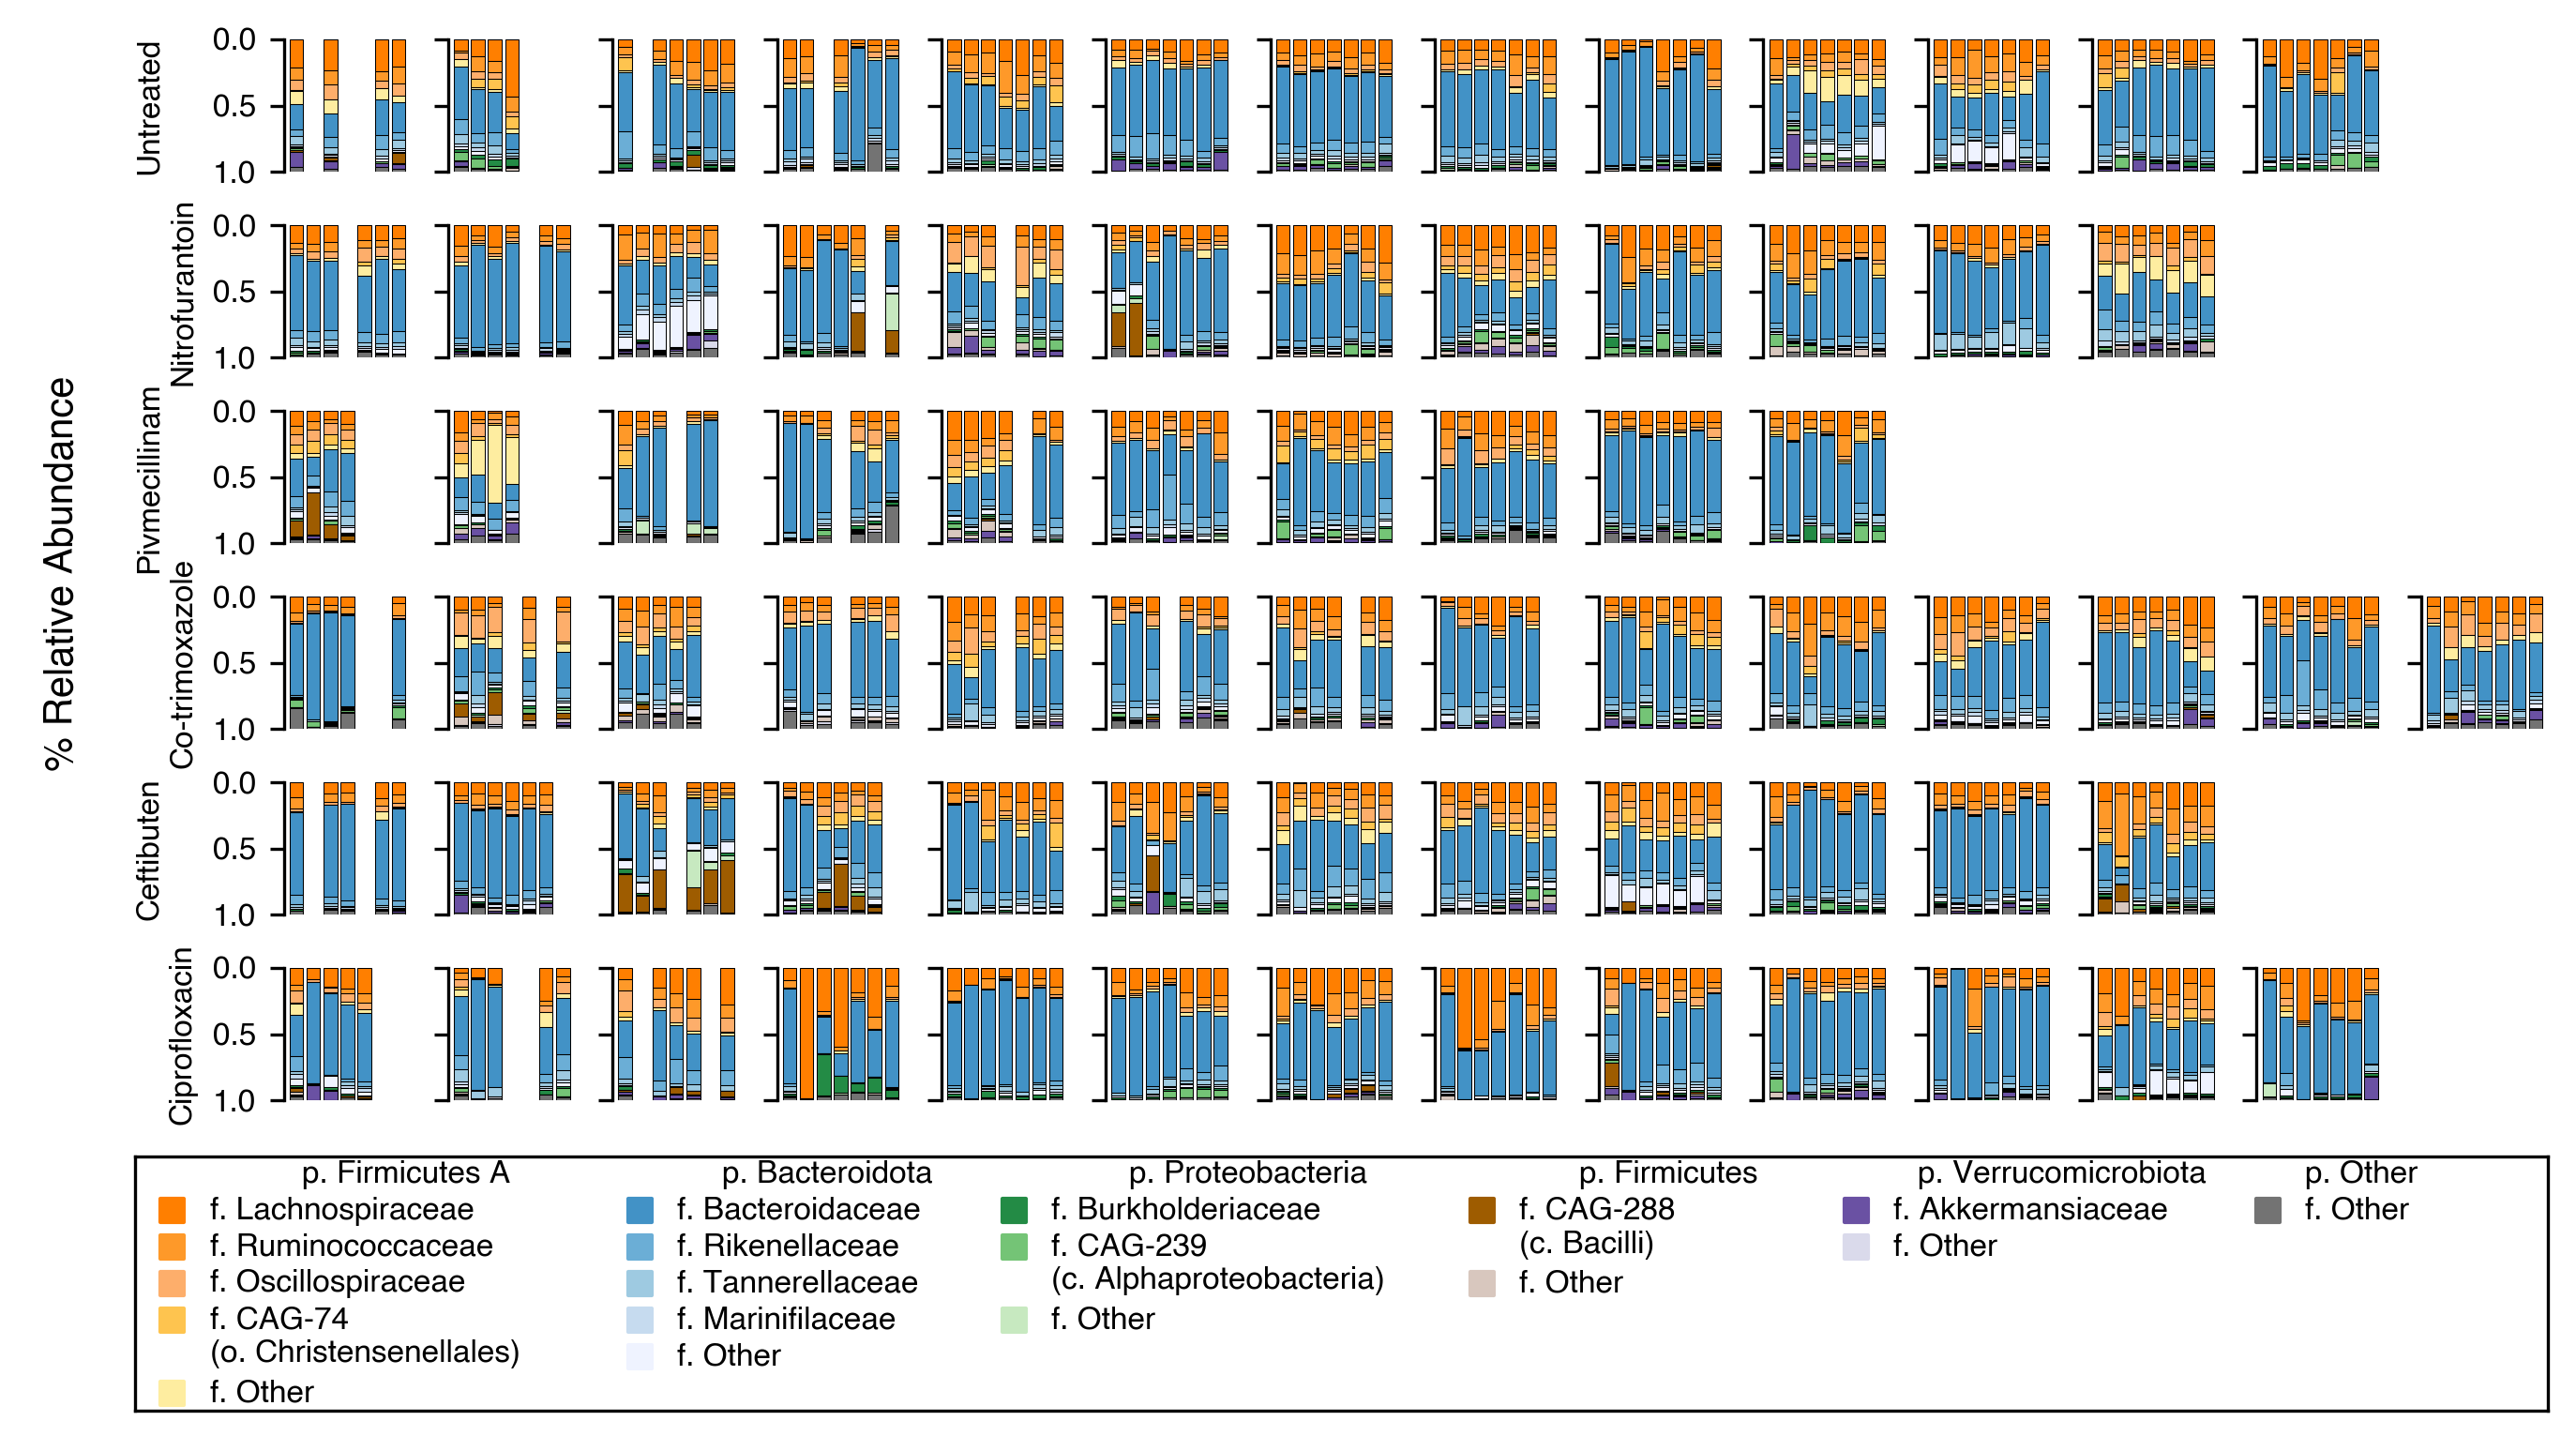

In [21]:
fig = plt.figure(dpi=300, constrained_layout=True, figsize=(9, 5), 
                 facecolor='None')
[[figy, figm], [_, figl]] = fig.subfigures(2, 2, width_ratios=[0.25, 8.75],
                                           height_ratios=[4, 1],
                                           facecolor='None')
gs = figm.add_gridspec(6, 14)
for i, (abx, abx_track) in enumerate(track_step2.groupby('abx_code2', sort=False)):
    for j, (id_, subj_track) in enumerate(abx_track.groupby('host_subject_id', sort=False)):
        if (i == 0) & (j == 0):
            ax = figm.add_subplot(gs[i, j])
        else:
            ax = figm.add_subplot(gs[i, j], sharex=ax, sharey=ax)
        ax.xaxis.set_tick_params(**hide_axes)
        ax.yaxis.set_tick_params(**left_axes)
        _plot_barplot(ax, id_, subj_track)
        _annot_missing(ax, id_, subj_track)
        ax.yaxis.set_tick_params(labelleft=(j == 0))
        if j == 0:
            ax.set_ylabel(abx_name[i], size=8)

axy = figy.add_subplot(1,1,1, facecolor='None')
axy.xaxis.set_tick_params(**hide_axes)
axy.yaxis.set_tick_params(**hide_axes)
axy.text(0.5, 0.5, '% Relative Abundance', size=10, 
         rotation=90, ha='center', va='center')
sn.despine(ax=axy, left=True, right=True, top=True, bottom=True)

# figll = figl.subfigures(1, 1, width_ratios=[5, 1], facecolor='None')
axll = figl.add_subplot(1,1,1)
axll.scatter(x='x', y='y', c='color', marker='s', data=table_fam_avg)
for fam, [x, y, tidy] in table_fam_avg[['x', 'y', 'tidy']].iterrows():
    axll.text(x=x + 0.1, y=y - 0.4, s=tidy, ha='left', va='top', size=8)
for phy, x in phylum_avg.items():
    axll.text(x + phylum_off[phy], y=0, 
              s=phy.replace("__", '. ').replace("_", ' '),
              ha='center', va='center', size=8)
axll.set_ylim(6.5, -0.5)
axll.set_xlim(-0.1, table_fam_avg['x'].max() + 0.75)
axll.xaxis.set_tick_params(**hide_axes)
axll.yaxis.set_tick_params(**hide_axes)

os.makedirs('./output/figures/', exist_ok=True)
fig.savefig('./output/figures/Figure_S3_indv_taxa.png', dpi=300, facecolor='None')
fig.savefig('./output/figures/Figure_S3_indv_taxa.pdf', dpi=300, facecolor='None')